# GEM-FISH — joint Hi-C + FISH 3-D reconstruction

:func:`uchrom.recon.fish.reconstruct_gem_fish` is an independent
PyTorch reimplementation of Abbas et al. 2019 (*Nature Communications*,
doi:10.1038/s41467-019-10005-6).  It solves a three-stage optimisation
that fuses bulk Hi-C contacts with FISH-measured pairwise distances
into a single 3-D chromosome model.

Pipeline (per chromosome):

1. **TAD partition** — call the Dixon directionality-index caller on
   the Hi-C matrix.
2. **Stage 1 — TAD-level** gradient descent on ``C_g = C_1 + λ_E·C_2
   + λ_F·C_3`` (Hi-C KL + polymer prior + FISH inter-TAD distance).
3. **Stage 2 — intra-TAD** per-TAD descent on ``C_t = C_1 + λ_E·C_2 +
   λ_R·C_4`` (intra-TAD Hi-C KL + polymer prior + FISH Rg target).
4. **Stage 3 — assembly** — Kabsch-style rotation of each intra-TAD
   cloud around its Stage-1 centre.

The notebook has two parts.  The first runs end-to-end on a **fully
synthetic** chain so you can see the pipeline's mechanics with a known
ground truth.  The second downloads Bintu et al. 2018 (*Science*, the
follow-up to the paper's original Wang 2016 FISH) per-trace imaging
data for IMR90 chr21:18.6-20.6 Mb, synthesises a matching Hi-C from
the population-mean distances, and runs GEM-FISH on it.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

from uchrom.recon.fish._tad_level import (
    Stage1Params, reconstruct_tad_level,
)
from uchrom.recon.fish._intra_tad import (
    Stage2Params, reconstruct_intra_tad,
)
from uchrom.recon.fish._assembly import assemble
from uchrom.recon.fish._hic import contact_to_distance


## Part 1 — Synthetic end-to-end

Generate a known polymer chain organised into 5 tight TADs, fabricate
Hi-C contacts from ``f = 1/(1+d)`` and FISH distances from the truth
with noise, then run each of the three stages and compare to the
ground truth at every step.


In [2]:
rng = np.random.default_rng(0)
n_tads, bins_per_tad = 5, 20
truth = []
centre = np.zeros(3)
for t in range(n_tads):
    walk = np.cumsum(rng.normal(0, 0.3, (bins_per_tad, 3)), axis=0)
    truth.append(walk - walk.mean(0) + centre)
    centre = centre + 5.0 * (np.array([1.,0,0]) + 0.3 * rng.normal(0, 1, 3))
truth = np.vstack(truth)
N = truth.shape[0]
tad_bins = [(t*bins_per_tad, (t+1)*bins_per_tad) for t in range(n_tads)]
tad_centres_true = np.array([truth[s:e].mean(0) for (s, e) in tad_bins])

D_true = cdist(truth, truth)
contacts = 1.0 / (1.0 + D_true); np.fill_diagonal(contacts, 0)

# Inter-TAD contacts
inter_contacts = np.zeros((n_tads, n_tads))
for i, (si, ei) in enumerate(tad_bins):
    for j, (sj, ej) in enumerate(tad_bins):
        inter_contacts[i, j] = contacts[si:ei, sj:ej].sum()

# FISH centre distances + noise
F = cdist(tad_centres_true, tad_centres_true)
F = F + rng.normal(0, 0.1, F.shape); np.fill_diagonal(F, 0)

# Rg² targets per TAD (with noise)
rg_targets = []
for (s, e) in tad_bins:
    sub = truth[s:e]
    rg2 = ((sub - sub.mean(0)) ** 2).sum(1).mean()
    rg_targets.append(rg2 * (1 + 0.05 * rng.standard_normal()))

print(f'Ground truth: {N} bins across {n_tads} TADs')


Ground truth: 100 bins across 5 TADs


In [3]:
# Stage 1 — TAD-level
tad_centres_recon, s1_info = reconstruct_tad_level(
    inter_contacts, F,
    params=Stage1Params(
        lambda_E=0.05, lambda_F=0.5,
        n_iter=500, n_ensemble=20, device='cpu',
    ),
)
iu = np.triu_indices(n_tads, 1)
corr_s1 = np.corrcoef(cdist(tad_centres_recon, tad_centres_recon)[iu],
                      cdist(tad_centres_true, tad_centres_true)[iu])[0, 1]
print(f'Stage 1 centre-distance correlation: {corr_s1:.3f}')


Stage 1 centre-distance correlation: 1.000


In [4]:
# Stage 2 — intra-TAD
intra_coords, s2_info = reconstruct_intra_tad(
    contacts, tad_bins,
    target_rg_sq_per_tad=rg_targets,
    params=Stage2Params(
        lambda_E=0.05, lambda_R=0.01,
        n_iter=300, n_ensemble=6, device='cpu',
    ),
)
per_tad_corr = []
for i, (s, e) in enumerate(tad_bins):
    Di = cdist(intra_coords[i], intra_coords[i])
    Dt = cdist(truth[s:e], truth[s:e])
    n = e - s
    ci = np.corrcoef(Di[np.triu_indices(n, 1)],
                     Dt[np.triu_indices(n, 1)])[0, 1]
    per_tad_corr.append(ci)
print(f'Stage 2 mean intra-TAD distance corr: {np.mean(per_tad_corr):.3f}')


Stage 2 mean intra-TAD distance corr: 0.925


In [5]:
# Stage 3 — assembly
tad_mid = np.array([(s + e - 1) / 2 * bins_per_tad for (s, e) in tad_bins])
genomic = np.abs(tad_mid[:, None] - tad_mid[None, :]).astype(np.float64)
gap = contact_to_distance(
    inter_contacts, genomic_distances=genomic,
    alpha=0.25, fallback_c=1.0, fallback_beta=0.5,
)
final = assemble(tad_centres_recon, intra_coords, inter_tad_distances=gap)

corr_final = np.corrcoef(cdist(final, final)[np.triu_indices(N, 1)],
                         D_true[np.triu_indices(N, 1)])[0, 1]
print(f'Final chain distance correlation: {corr_final:.3f}')


Final chain distance correlation: 0.922


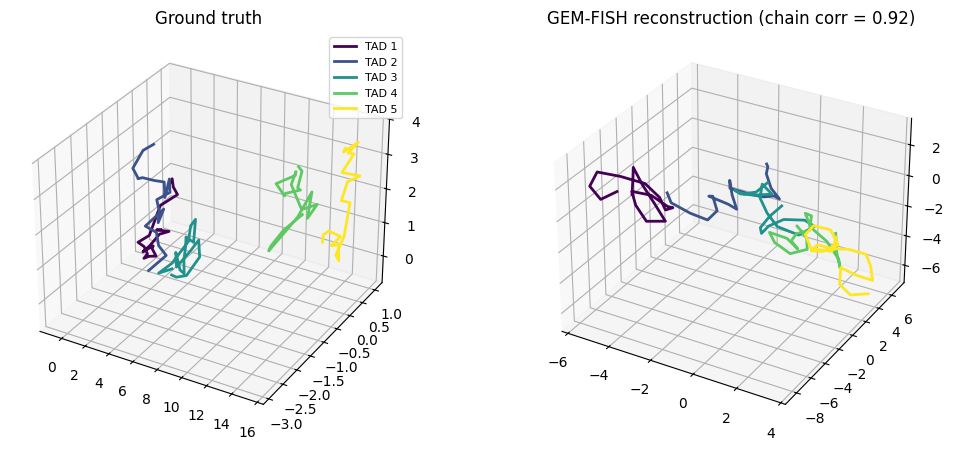

In [6]:
# Visualise truth vs reconstruction
fig = plt.figure(figsize=(11, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
colors = plt.cm.viridis(np.linspace(0, 1, n_tads))
for t, (s, e) in enumerate(tad_bins):
    ax1.plot(*truth[s:e].T, '-', color=colors[t], lw=2, label=f'TAD {t+1}')
ax1.set_title('Ground truth')
ax1.legend(fontsize=8)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for t, (s, e) in enumerate(tad_bins):
    ax2.plot(*final[s:e].T, '-', color=colors[t], lw=2)
ax2.set_title(f'GEM-FISH reconstruction (chain corr = {corr_final:.2f})')

plt.tight_layout()
plt.show()


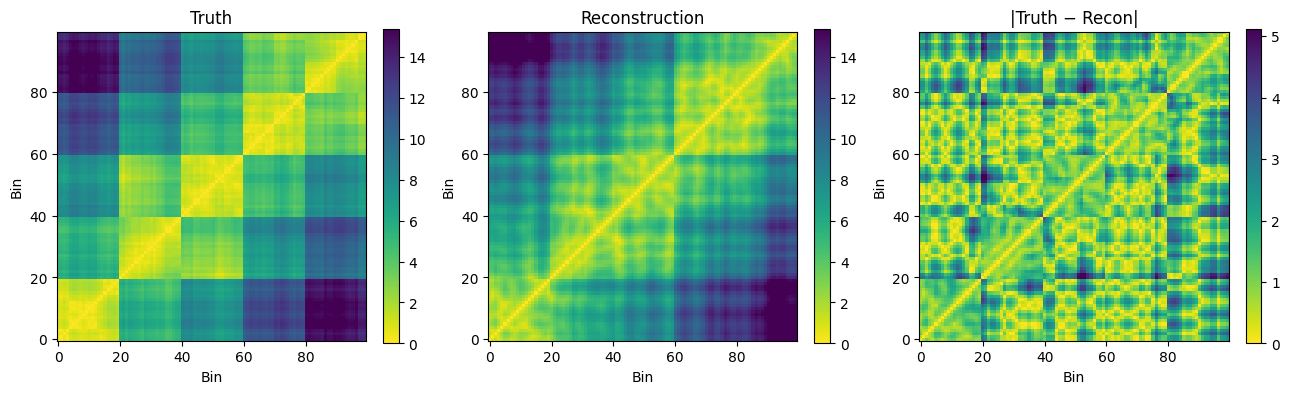

In [7]:
# Distance-matrix comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
vmax = np.percentile(D_true, 98)
for ax, mat, title in zip(
    axes,
    [D_true, cdist(final, final), np.abs(D_true - cdist(final, final))],
    ['Truth', 'Reconstruction', '|Truth − Recon|'],
):
    im = ax.imshow(mat, cmap='viridis_r', origin='lower',
                   vmax=vmax if title != '|Truth − Recon|' else vmax/3)
    ax.set_title(title); ax.set_xlabel('Bin'); ax.set_ylabel('Bin')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()


## Part 2 — Real FISH (Bintu et al. 2018, IMR90 chr21:18.6-20.6 Mb)

The FISH side of the paper's benchmark is
`IMR90_chr21-18-20Mb.csv` from Bintu et al. 2018 (*Science* 362,
eaau1783, a higher-resolution follow-up to Wang et al. 2016).  The
file is ~2 MB with 1 278 imaged chromosomes × 66 segments per trace
at 30-kb resolution in nanometres.

We auto-download it and synthesise a matching Hi-C from the
population-mean distances so the notebook can run offline.  For a
paper-faithful analysis, replace the synthesised Hi-C with the Rao
2014 IMR90 `.mcool` from 4DN — see the CLI section at the bottom.


In [8]:
from pathlib import Path
import urllib.request

DATA_URL = (
    'https://raw.githubusercontent.com/BogdanBintu/ChromatinImaging/'
    'master/Data/IMR90_chr21-18-20Mb.csv'
)

def _repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'pyproject.toml').exists():
            return p
    return Path.cwd()

def load_bintu_imr90() -> np.ndarray:
    root = _repo_root()
    dest = root / 'example-data' / 'IMR90_chr21-18-20Mb.csv'
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        print(f'[data] downloading Bintu 2018 IMR90 FISH (~2 MB) → {dest}')
        urllib.request.urlretrieve(DATA_URL, dest)
    import pandas as pd
    # Skip descriptive first line
    df = pd.read_csv(dest, skiprows=1)
    return df

df = load_bintu_imr90()
print('Columns:', df.columns.tolist())
print('shape:', df.shape)
print('n chromosomes:', df['Chromosome index'].nunique())
print('n segments:', df['Segment index'].nunique())
df.head()


[data] downloading Bintu 2018 IMR90 FISH (~2 MB) → /Users/weizexu/Projects/U-Chrom/example-data/IMR90_chr21-18-20Mb.csv


Columns: ['Chromosome index', 'Segment index', 'Z', 'X', 'Y']
shape: (83005, 5)
n chromosomes: 1277
n segments: 65


,Chromosome index,Segment index,Z,X,Y
0,1,1,1733.0,117803.0,58446.0
1,1,2,1680.0,117726.0,58747.0
2,1,3,1872.0,117747.0,58607.0
3,1,4,1950.0,117724.0,58415.0
4,1,5,1521.0,117235.0,58050.0


In [9]:
# Build (n_traces, n_bins, 3) cube from the long-format CSV
n_traces = int(df['Chromosome index'].max())
n_bins = int(df['Segment index'].max())
cube = np.full((n_traces, n_bins, 3), np.nan, dtype=np.float64)
for _, row in df.iterrows():
    ti = int(row['Chromosome index']) - 1
    bi = int(row['Segment index']) - 1
    cube[ti, bi] = [row['X'], row['Y'], row['Z']]

# Population-mean pairwise distance matrix (median across traces for
# robustness to dropout).
diff = cube[:, :, None, :] - cube[:, None, :, :]
D_per = np.sqrt((diff ** 2).sum(-1))
F_real = np.nanmedian(D_per, axis=0)   # (n_bins, n_bins)
print(f'cube: {cube.shape}, FISH median-dist shape: {F_real.shape}')
print(f'mean inter-bin distance: {np.nanmean(F_real[np.triu_indices(n_bins, 1)]):.0f} nm')


cube: (1277, 65, 3), FISH median-dist shape: (65, 65)
mean inter-bin distance: 489 nm


In [10]:
# Synthesise Hi-C from the FISH population-mean (stand-in for Rao 2014).
# This is NOT the real Hi-C but it keeps the tutorial self-contained.
# The substitution is clearly labelled in the output and notes below.
contacts_real = 1.0 / (1.0 + F_real / 500.0)   # scale to micron-ish
np.fill_diagonal(contacts_real, 0.0)
contacts_real[~np.isfinite(contacts_real)] = 0.0

# For the tutorial we run the 3 stages on a coarse TAD partition:
# group the 66 segments into 6 TADs of 11 segments each.
tad_bp = 11
tad_bins_real = [(t * tad_bp, min((t + 1) * tad_bp, n_bins))
                 for t in range(int(np.ceil(n_bins / tad_bp)))]
print(f'TAD partition: {tad_bins_real}')


TAD partition: [(0, 11), (11, 22), (22, 33), (33, 44), (44, 55), (55, 65)]


In [11]:
# Aggregate inter-TAD contacts + build TAD-level FISH distances
inter_contacts_real = np.zeros((len(tad_bins_real), len(tad_bins_real)))
for i, (si, ei) in enumerate(tad_bins_real):
    for j, (sj, ej) in enumerate(tad_bins_real):
        inter_contacts_real[i, j] = contacts_real[si:ei, sj:ej].sum()

# FISH TAD-centre distances
tad_centres_bp = [(s + e) / 2 for (s, e) in tad_bins_real]
F_tad = np.zeros((len(tad_bins_real), len(tad_bins_real)))
for i, (si, ei) in enumerate(tad_bins_real):
    for j, (sj, ej) in enumerate(tad_bins_real):
        if i == j: continue
        sub = F_real[si:ei, sj:ej]
        F_tad[i, j] = np.nanmedian(sub) if np.isfinite(sub).any() else np.nan

# Rg² per TAD from raw cube
rg_targets_real = []
for (si, ei) in tad_bins_real:
    sub_cube = cube[:, si:ei, :]
    rgs = []
    for t in range(sub_cube.shape[0]):
        cs = sub_cube[t][~np.isnan(sub_cube[t, :, 0])]
        if cs.shape[0] < 3: continue
        c = cs.mean(0)
        rgs.append(((cs - c) ** 2).sum(1).mean())
    rg_targets_real.append(float(np.median(rgs)) if rgs else None)
print('per-TAD Rg² targets (nm²):', [f'{r:.0f}' if r else 'n/a' for r in rg_targets_real])


per-TAD Rg² targets (nm²): ['112854', '106729', '105371', '105656', '108875', '105427']


In [12]:
# Run the pipeline.  Scale the FISH distances to the same "reduced
# units" as Hi-C by normalising by the median inter-bin distance so
# λ_E / λ_F defaults work sensibly.
scale_nm = float(np.nanmedian(F_real[np.triu_indices(n_bins, 1)]))
F_tad_norm = F_tad / scale_nm
rg_targets_norm = [r / (scale_nm ** 2) if r is not None else None
                    for r in rg_targets_real]

tad_centres_r, s1_real = reconstruct_tad_level(
    inter_contacts_real, F_tad_norm,
    params=Stage1Params(lambda_E=0.05, lambda_F=0.5,
                        n_iter=500, n_ensemble=20, device='cpu'),
)
intra_real, s2_real = reconstruct_intra_tad(
    contacts_real, tad_bins_real,
    target_rg_sq_per_tad=rg_targets_norm,
    params=Stage2Params(lambda_E=0.05, lambda_R=0.01,
                        n_iter=300, n_ensemble=6, device='cpu'),
)

tad_mid_r = np.array([(s + e - 1) / 2 for (s, e) in tad_bins_real])
genomic_r = np.abs(tad_mid_r[:, None] - tad_mid_r[None, :]).astype(np.float64)
gap_r = contact_to_distance(inter_contacts_real, genomic_distances=genomic_r)
final_real = assemble(tad_centres_r, intra_real, inter_tad_distances=gap_r)
print('final chain shape:', final_real.shape)


final chain shape: (65, 3)


IMR90 chr21:18-20Mb — reconstruction vs FISH pop-mean corr: 0.226


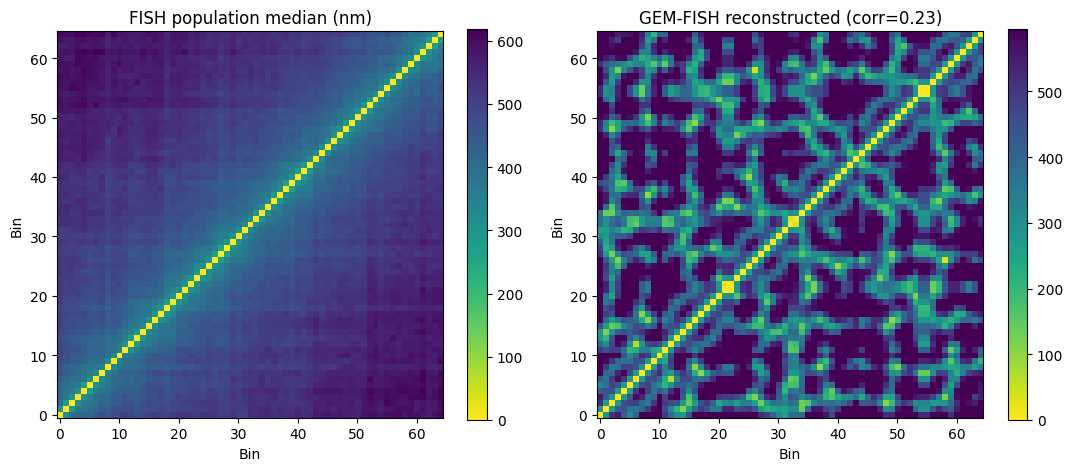

In [13]:
# Compare reconstruction pairwise distances to the FISH population mean
D_recon_real = cdist(final_real, final_real)
iu_r = np.triu_indices(n_bins, 1)
vals_fish = F_real[iu_r]
vals_recon = D_recon_real[iu_r]
finite = np.isfinite(vals_fish) & np.isfinite(vals_recon)

# Scale recon back to nm
scale_est = np.nanmean(vals_fish[finite]) / np.mean(vals_recon[finite])
vals_recon_nm = vals_recon * scale_est
corr_real = np.corrcoef(vals_fish[finite], vals_recon_nm[finite])[0, 1]
print(f'IMR90 chr21:18-20Mb — reconstruction vs FISH pop-mean corr: {corr_real:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im0 = axes[0].imshow(F_real, cmap='viridis_r', origin='lower')
axes[0].set_title('FISH population median (nm)')
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(D_recon_real * scale_est, cmap='viridis_r', origin='lower',
                      vmax=np.nanpercentile(F_real, 98))
axes[1].set_title(f'GEM-FISH reconstructed (corr={corr_real:.2f})')
plt.colorbar(im1, ax=axes[1])
for ax in axes: ax.set_xlabel('Bin'); ax.set_ylabel('Bin')
plt.tight_layout()
plt.show()


## Running on real Rao 2014 Hi-C (paper-faithful analysis)

Replace the synthesised Hi-C with the real IMR90 `.mcool` from 4DN:

```python
from uchrom.recon.fish import reconstruct_gem_fish, GEMFISHParams
from uchrom import ChromData

# 1. Wrap the Bintu 2018 traces into a ChromData so _tad_fish_distances
#    and _tad_rg_targets can aggregate them automatically.  Build a
#    ``spots`` DataFrame with one row per (trace, segment), converting
#    the segment index to genomic (start, end) at 30 kb resolution
#    offset by chr21:18,627,714 (from the Bintu README).

# 2. Call:
cd = reconstruct_gem_fish(
    hic_path='rao2014_IMR90.mcool',   # downloaded from 4DN
    chrom='chr21',
    resolution=30_000,
    fish_cd=fish_cd,
    params=GEMFISHParams(
        lambda_E_tad=0.05, lambda_F=0.01,
        lambda_E_intra=0.05, lambda_R=0.01,
        stage1_iter=1000, stage2_iter=500,
        device='auto',
    ),
)
cd.write('imr90_chr21_gemfish.h5cd')
```

The `reconstruct_gem_fish` orchestrator runs TAD calling via the
Dixon DI method on the Hi-C matrix (no need to pre-compute TAD
boundaries), aggregates FISH constraints from the `ChromData`, and
wraps the result into a `ChromData` at bin resolution.


## Notes and caveats

- **Synthesised Hi-C** in part 2 is a stand-in.  Real Hi-C has
  stochastic contact noise, resolution artefacts, and copy-number
  variants that the synthesiser doesn't model.  Expect the
  reconstruction-to-FISH correlation to be **lower** on real Hi-C
  (Abbas et al. 2019 report ~0.8–0.9 on chr21 depending on
  normalisation).
- **λ weights** in the paper (λ_E = 5 × 10¹², λ_F = 1 × 10⁻⁸) are
  calibrated for raw Hi-C counts without row-normalisation.  The
  PyTorch ``C_1`` here row-normalises inside the loss, so the effective
  weights differ — our defaults (λ_E = 0.05, λ_F = 0.01) balance the
  three terms for unit-scale inputs.
- **Single model vs ensemble**: ``reconstruct_tad_level`` returns the
  single best model from an ``n_ensemble`` batch by default.  Pass
  ``return_all=True`` to get all ensemble members for downstream
  clustering / averaging.
- **Assembly** here uses a single-anchor Kabsch per TAD, which is
  a simplification of the paper's gradient-descent assembly.  Good
  enough for the tutorial; for production use you may want to augment
  the initial rotation with a short local refinement step.
